# 🤖 Training & Testing Model Klasifikasi Sentimen: Logistic Regression
### Penelitian Publikasi Ilmiah - Analisis Sentimen Usulan Reklasifikasi MSCI Indonesia

Notebook ini memuat seluruh tahapan eksperimen machine learning menggunakan algoritma **Logistic Regression (Multinomial)**:
1. **Pemuatan Dataset Preprocessing:** Mengambil data hasil cleaning, tokenization, stopword removal, dan stemming Sastrawi.
2. **Ekstraksi Fitur TF-IDF:** Mengubah teks menjadi representasi vektor numerik berdimensi tinggi.
3. **Train-Test Split (80:20):** Pembagian data latih dan data uji secara *stratified*.
4. **Penyeimbangan Data Latih dengan SMOTE:** Mencegah bias kelas mayoritas tanpa menyebabkan *data leakage*.
5. **Pelatihan Model & Tuning Hyperparameter:** Eksperimen optimasi *C*, *penalty*, dan *solver* dengan *Grid Search Cross-Validation*.
6. **Pengujian & Evaluasi Performa:** Pengukuran Akurasi, Precision, Recall, F1-Score, dan Confusion Matrix pada data uji alami.
7. **Uji Coba Prediksi Teks Baru:** Fungsi inferensi kalimat tweet baru dengan estimasi probabilitas per kelas.
8. **Penyimpanan Model:** Ekspor model Logistic Regression dan TF-IDF vectorizer ke format `.pkl` (Joblib).

---  
## 0. Instalasi Pustaka / Dependencies (Opsional)
Jalankan sel di bawah ini jika pustaka belum terpasang di lingkungan Python / komputer Anda (misal jika dijalankan di Google Colab atau virtual environment baru).

In [1]:
# Instalasi seluruh library yang dibutuhkan untuk NLP, ML, dan Visualisasi
%pip install -q pandas numpy scikit-learn imbalanced-learn Sastrawi matplotlib seaborn joblib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


---  
## 1. Inisialisasi Pustaka & Konfigurasi Lingkungan

In [2]:
import sys
# Pastikan encoding UTF-8 untuk konsol Windows
if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8', errors='replace')

import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Scikit-Learn Modules
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    classification_report, 
    confusion_matrix
)

# Imbalanced-Learn (SMOTE)
from imblearn.over_sampling import SMOTE

# Sastrawi untuk inferensi teks baru
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# Konfigurasi visualisasi grafik
sns.set_theme(style='whitegrid')

print("[OK] Seluruh pustaka berhasil dimuat!")

[OK] Seluruh pustaka berhasil dimuat!


---  
## 2. Pemuatan Dataset Hasil Preprocessing

In [4]:
import os
import pandas as pd

# Prioritaskan dataset yang SUDAH memiliki label sentimen
file_path = 'dataset_msci_labeled.csv'
if not os.path.exists(file_path):
    file_path = 'dataset_msci_bersih.csv'
if not os.path.exists(file_path):
    file_path = 'dataset_msci_preprocessed.csv'

if not os.path.exists(file_path):
    raise FileNotFoundError("Tidak ada file dataset yang ditemukan! Pastikan file CSV tersedia di folder kerja.")

df = pd.read_csv(file_path)
print(f"[OK] Dataset berhasil dimuat dari: '{file_path}'")
print(f"Total baris data : {df.shape[0]} tweet")
print(f"Total kolom      : {df.shape[1]} kolom")

# Validasi keberadaan kolom 'sentimen'
if 'sentimen' not in df.columns:
    raise KeyError(
        f"File '{file_path}' belum memiliki kolom 'sentimen'. "
        "Silakan jalankan cell pelabelan InSet Lexicon terlebih dahulu untuk menghasilkan 'dataset_msci_labeled.csv'."
    )

# Pastikan tidak ada missing values pada kolom teks input dan label
text_col = 'stemmed_text' if 'stemmed_text' in df.columns else 'full_text'
df = df.dropna(subset=[text_col, 'sentimen']).reset_index(drop=True)

print(f"\nDistribusi Label Sentimen Asli:")
print(df['sentimen'].value_counts())
print(f"\nPersentase Label Sentimen Asli (%):")
print((df['sentimen'].value_counts(normalize=True) * 100).round(2))

# Tampilkan sampel 3 data teratas
display(df[[text_col, 'sentimen']].head(3))

[OK] Dataset berhasil dimuat dari: 'dataset_msci_labeled.csv'
Total baris data : 1039 tweet
Total kolom      : 23 kolom

Distribusi Label Sentimen Asli:
sentimen
Negatif    809
Positif    115
Netral     109
Name: count, dtype: int64

Persentase Label Sentimen Asli (%):
sentimen
Negatif    78.32
Positif    11.13
Netral     10.55
Name: proportion, dtype: float64


,stemmed_text,sentimen
0,sentimen msci jadi salah satu faktor turut bay...,Negatif
1,penjelsan benix soal ihsg jatuh ihsg pernah se...,Negatif
2,msci jadi momok ihsg anjlok rp triliun lenyap,Negatif


---  
## 3. Ekstraksi Fitur TF-IDF (Term Frequency - Inverse Document Frequency)
Mengubah teks hasil stemming menjadi matriks numerik berbobot TF-IDF.

In [5]:
# Inisialisasi TfidfVectorizer
# Batasi ke 1000 fitur term teratas yang paling representatif
tfidf = TfidfVectorizer(max_features=1000)

X = tfidf.fit_transform(df[text_col].astype(str)).toarray()
y = df['sentimen']

print(f"[OK] Ekstraksi TF-IDF Selesai!")
print(f" - Dimensi Matriks Fitur X : {X.shape[0]} baris x {X.shape[1]} fitur")
print(f" - Dimensi Target Label y   : {len(y)} label")

[OK] Ekstraksi TF-IDF Selesai!
 - Dimensi Matriks Fitur X : 1033 baris x 1000 fitur
 - Dimensi Target Label y   : 1033 label


---  
## 4. Pembagian Data (Train-Test Split: 80% Latih, 20% Uji)
Pembagian menggunakan opsi `stratify=y` untuk menjaga proporsi distribusi kelas sentimen yang seimbang antara subset latih dan uji.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"Jumlah Data Training : {len(y_train)} sampel (80%)")
print(f"Jumlah Data Testing  : {len(y_test)} sampel (20%)")
print("\nDistribusi Kelas pada Data Training (Sebelum SMOTE):")
print(y_train.value_counts())

Jumlah Data Training : 826 sampel (80%)
Jumlah Data Testing  : 207 sampel (20%)

Distribusi Kelas pada Data Training (Sebelum SMOTE):
sentimen
Negatif    647
Positif     92
Netral      87
Name: count, dtype: int64


---  
## 5. Penyeimbangan Data Training dengan SMOTE
> **Catatan Ilmiah:** SMOTE hanya diterapkan pada **data training** (`X_train`, `y_train`) untuk mencegah *data leakage*. Data uji (`X_test`, `y_test`) dibiarkan dalam kondisi alami untuk mengukur kemampuan generalisasi model yang sebenarnya.

In [7]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("=== Perbandingan Jumlah Sampel Data Training ===")
print(f"Sebelum SMOTE : {len(y_train)} baris")
print(f"Setelah SMOTE : {len(y_train_res)} baris\n")
print("Distribusi Kelas Data Training Setelah SMOTE:")
print(y_train_res.value_counts())

=== Perbandingan Jumlah Sampel Data Training ===
Sebelum SMOTE : 826 baris
Setelah SMOTE : 1941 baris

Distribusi Kelas Data Training Setelah SMOTE:
sentimen
Negatif    647
Netral     647
Positif    647
Name: count, dtype: int64


---  
## 6. Pelatihan Model Logistic Regression & Hyperparameter Tuning
Logistic Regression memodelkan probabilitas setiap tweet masuk ke dalam masing-masing kelas sentimen dengan fungsi *Sigmoid / Softmax*.
Kita melakukan perbandingan hyperparameter menggunakan `GridSearchCV`:
- **C (Inverse of Regularization Strength):** `[0.1, 1.0, 5.0, 10.0]`
- **Solver:** `['lbfgs', 'saga']`
- **Max Iterations:** `1000` (agar konvergensi optimal)
- **Cross Validation:** 5-Fold Stratified CV
- **n_jobs:** `1` (aman dan stabil pada arsitektur Windows/Jupyter)

In [8]:
# Definisi Ruang Pencarian Hyperparameter (Grid Search)
param_grid = {
    'C': [0.1, 1.0, 5.0, 10.0],
    'solver': ['lbfgs', 'saga'],
    'max_iter': [1000]
}

print("[INFO] Memulai Grid Search Cross-Validation (5-Fold) untuk Logistic Regression...")
grid_lr = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=1,
    verbose=1
)

# Latih pada data training hasil SMOTE
grid_lr.fit(X_train_res, y_train_res)

best_lr = grid_lr.best_estimator_
print("\n[OK] Pelatihan Model Logistic Regression Selesai!")
print(f"Hyperparameter Terbaik : {grid_lr.best_params_}")
print(f"Skor Rata-rata F1-Macro CV : {grid_lr.best_score_:.4f}")

[INFO] Memulai Grid Search Cross-Validation (5-Fold) untuk Logistic Regression...
Fitting 5 folds for each of 8 candidates, totalling 40 fits

[OK] Pelatihan Model Logistic Regression Selesai!
Hyperparameter Terbaik : {'C': 10.0, 'max_iter': 1000, 'solver': 'saga'}
Skor Rata-rata F1-Macro CV : 0.9592


---  
## 7. Pengujian & Evaluasi Performa Model (Testing)
Menguji model Logistic Regression terbaik menggunakan data testing alami (`X_test`, `y_test`).

In [9]:
# Prediksi label pada data testing
y_pred = best_lr.predict(X_test)

# Perhitungan metrik evaluasi
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)

prec_weighted = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec_weighted = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("="*55)
print("    RINGKASAN EVALUASI MODEL LOGISTIC REGRESSION     ")
print("="*55)
print(f"Akurasi (Accuracy)        : {acc * 100:.2f}%")
print(f"Precision (Macro Average) : {prec_macro * 100:.2f}%")
print(f"Recall (Macro Average)    : {rec_macro * 100:.2f}%")
print(f"F1-Score (Macro Average)  : {f1_macro * 100:.2f}%")
print("-"*55)
print(f"F1-Score (Weighted)       : {f1_weighted * 100:.2f}%")
print("="*55)

print("\nLaporan Klasifikasi Terperinci (Classification Report):")
print(classification_report(y_test, y_pred, zero_division=0))

    RINGKASAN EVALUASI MODEL LOGISTIC REGRESSION     
Akurasi (Accuracy)        : 81.16%
Precision (Macro Average) : 64.47%
Recall (Macro Average)    : 60.29%
F1-Score (Macro Average)  : 61.21%
-------------------------------------------------------
F1-Score (Weighted)       : 80.19%

Laporan Klasifikasi Terperinci (Classification Report):
              precision    recall  f1-score   support

     Negatif       0.88      0.91      0.89       162
      Netral       0.52      0.59      0.55        22
     Positif       0.54      0.30      0.39        23

    accuracy                           0.81       207
   macro avg       0.64      0.60      0.61       207
weighted avg       0.80      0.81      0.80       207



---  
## 8. Visualisasi Evaluasi (Confusion Matrix & Grafik Performa)

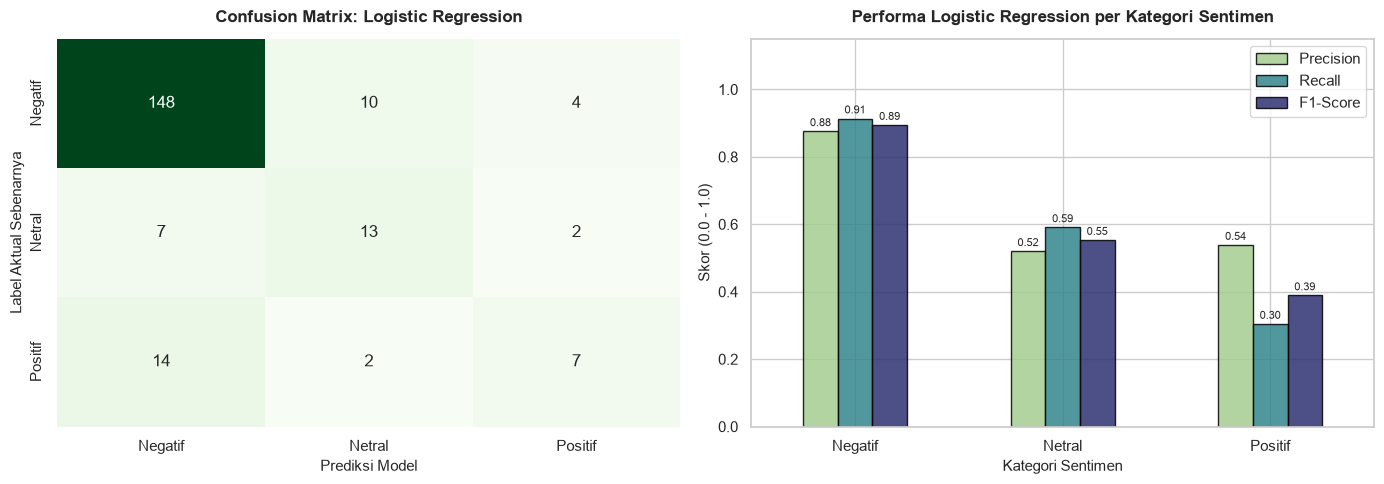

In [10]:
labels_order = ['Negatif', 'Netral', 'Positif']
cm = confusion_matrix(y_test, y_pred, labels=labels_order)

plt.figure(figsize=(14, 5))

# Subplot 1: Confusion Matrix Heatmap
plt.subplot(1, 2, 1)
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Greens', 
    xticklabels=labels_order, 
    yticklabels=labels_order,
    cbar=False
)
plt.title('Confusion Matrix: Logistic Regression', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Prediksi Model', fontsize=11)
plt.ylabel('Label Aktual Sebenarnya', fontsize=11)

# Subplot 2: Metrik per Kelas Sentimen
plt.subplot(1, 2, 2)
report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
metrics_df = pd.DataFrame({
    'Precision': [report_dict[c]['precision'] for c in labels_order],
    'Recall': [report_dict[c]['recall'] for c in labels_order],
    'F1-Score': [report_dict[c]['f1-score'] for c in labels_order]
}, index=labels_order)

ax2 = metrics_df.plot(kind='bar', ax=plt.gca(), colormap='crest', edgecolor='black', alpha=0.85)
plt.title('Performa Logistic Regression per Kategori Sentimen', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Kategori Sentimen', fontsize=11)
plt.ylabel('Skor (0.0 - 1.0)', fontsize=11)
plt.ylim(0, 1.15)
plt.legend(loc='upper right', frameon=True)
plt.xticks(rotation=0)

# Tambahkan label nilai di atas batang grafik
for container in ax2.containers:
    ax2.bar_label(container, fmt='%.2f', fontsize=8, padding=2)

plt.tight_layout()
plt.show()

---  
## 9. Pengujian Kalimat Baru & Probabilitas Keyakinan (Softmax)

In [12]:
import re
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# Inisialisasi fungsi preprocessing mandiri untuk inferensi kalimat baru
stemmer_inf = StemmerFactory().create_stemmer()
stopword_inf = StopWordRemoverFactory().create_stop_word_remover()

def predict_sentiment_lr(text):
    # 1. Cleaning
    text_c = re.sub(r'https?://\S+|www\.\S+', '', str(text))
    text_c = re.sub(r'[@#]\S+', '', text_c)
    text_c = re.sub(r'[^\w\s]', ' ', text_c)
    text_c = re.sub(r'\d+', ' ', text_c).lower().strip()
    
    # 2. Stopword & Stemming
    text_stop = stopword_inf.remove(text_c)
    text_stem = stemmer_inf.stem(text_stop)
    
    # 3. Vectorization & Prediction
    vec = tfidf.transform([text_stem]).toarray()
    pred = best_lr.predict(vec)[0]
    proba = best_lr.predict_proba(vec)[0]
    classes = best_lr.classes_
    proba_dict = {classes[i]: round(proba[i] * 100, 2) for i in range(len(classes))}
    
    return pred, proba_dict, text_stem

# Contoh Uji Coba Beberapa Kalimat Simulasi
contoh_kalimat = [
    "IHSG anjlok sangat dalam akibat sentimen negatif MSCI dan investor asing panik jual!",
    "Pasar saham Indonesia berhasil rebound menguat tajam hari ini, potensi cuan terbuka lebar!",
    "MSCI merilis jadwal tinjauan berkala indeks pasar saham Indonesia pada pekan depan."
]

print("=== HASIL PREDIKSI TWEET BARU (LOGISTIC REGRESSION) ===\n")
for k in contoh_kalimat:
    label, proba, stem_res = predict_sentiment_lr(k)
    print(f"Teks Asli    : \"{k}\"")
    print(f"Teks Stem    : \"{stem_res}\"")
    print(f"Prediksi     : [{label.upper()}]")
    print(f"Probabilitas : {proba}\n")

=== HASIL PREDIKSI TWEET BARU (LOGISTIC REGRESSION) ===

Teks Asli    : "IHSG anjlok sangat dalam akibat sentimen negatif MSCI dan investor asing panik jual!"
Teks Stem    : "ihsg anjlok sangat akibat sentimen negatif msci investor asing panik jual"
Prediksi     : [NEGATIF]
Probabilitas : {'Negatif': np.float64(92.36), 'Netral': np.float64(6.23), 'Positif': np.float64(1.41)}

Teks Asli    : "Pasar saham Indonesia berhasil rebound menguat tajam hari ini, potensi cuan terbuka lebar!"
Teks Stem    : "pasar saham indonesia hasil rebound kuat tajam hari potensi cuan buka lebar"
Prediksi     : [NEGATIF]
Probabilitas : {'Negatif': np.float64(56.38), 'Netral': np.float64(2.1), 'Positif': np.float64(41.52)}

Teks Asli    : "MSCI merilis jadwal tinjauan berkala indeks pasar saham Indonesia pada pekan depan."
Teks Stem    : "msci rilis jadwal tinjau kala indeks pasar saham indonesia pekan depan"
Prediksi     : [NEGATIF]
Probabilitas : {'Negatif': np.float64(50.98), 'Netral': np.float64(3.56), 'Po

---  
## 10. Penyimpanan Model Logistic Regression & TF-IDF Vectorizer
Menyimpan model terbaik dan vectorizer ke dalam berkas binary `.pkl` agar dapat digunakan kembali tanpa perlu melatih ulang.

In [13]:
os.makedirs('models', exist_ok=True)

model_filename = 'models/logistic_regression_model.pkl'
vectorizer_filename = 'models/tfidf_vectorizer.pkl'

joblib.dump(best_lr, model_filename)
joblib.dump(tfidf, vectorizer_filename)

print(f"[OK] Model Logistic Regression berhasil disimpan ke : '{model_filename}'")
print(f"[OK] TF-IDF Vectorizer berhasil disimpan ke          : '{vectorizer_filename}'")

[OK] Model Logistic Regression berhasil disimpan ke : 'models/logistic_regression_model.pkl'
[OK] TF-IDF Vectorizer berhasil disimpan ke          : 'models/tfidf_vectorizer.pkl'
